<div style="background: linear-gradient(135deg, #1e50a0 0%, #2e6cc0 100%); padding: 36px 40px; border-radius: 10px; color: white; margin-bottom: 20px;">
    <h1 style="color: white; margin: 0 0 8px 0; font-size: 2em;">Introduction to Deep Learning | MNIST Case</h1>
    <h2 style="color: #c8dcff; margin: 0 0 12px 0; font-weight: normal; font-size: 1.3em;">Multi-Layer Perceptron in PyTorch</h2>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Tensors on GPU / CPU &nbsp;·&nbsp; nn.Module &nbsp;·&nbsp; Autograd &nbsp;·&nbsp; torch.optim (SGD, Adam) &nbsp;·&nbsp; Dropout &nbsp;·&nbsp; Gradient check &nbsp;·&nbsp; PyTorch only</p>
    <hr>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Author: A.S.Grm (aleksander.grm@fpp.uni-lj.si), 2026</p>
</div>

## 1. Introduction

### 1.1 The task

The **MNIST** data set (LeCun et al., 1998) contains $70\,000$ grey-scale images of hand-written digits
$0,1,\dots,9$, each $28\times28$ pixels:

| Split | Images | Use in this notebook |
|---|---:|---|
| training set | 60 000 | weights are fitted here (we often use only a small subset) |
| test set | 10 000 | measured **once**, at the very end, to estimate performance on unseen data |

Each pixel is an integer in $[0,255]$ (0 = black background, 255 = white ink). The goal is a function

$$f_\theta:\ \mathbb R^{784} \to \mathbb R^{10},\qquad \hat k = \arg\max_c f_\theta(x)_c ,$$

that maps a flattened image $x$ to ten class scores and predicts the digit $\hat k$ with the largest score.
$\theta$ denotes all trainable weights and biases. We use the simplest deep-learning model that solves the
task well: the **multi-layer perceptron (MLP)**, also called a fully-connected feed-forward network.

### 1.2 How this notebook is built

The network is written with **PyTorch only**: tensors live on the selected compute device (CUDA / ROCm GPU, Apple-Silicon MPS or CPU), the model is an `nn.Module`, gradients come from **Autograd** and the parameter updates from `torch.optim`. Every framework call is linked back to the equation it implements.

There is a twin notebook that implements **exactly the same experiments in NumPy**. The section
numbers, the hyper-parameters and the loss definitions are identical, so the two notebooks can be read
side by side and their results compared directly.

The notebook combines four earlier codes into one consistent story:

| Earlier code | What it contained | Where it is now |
|---|---|---|
| `chapter_8_1` | one-image-at-a-time SGD, with and without dropout (Trask, ch. 8) | Experiment A |
| `chapter_8_2_batch` | mini-batch SGD: a naive (wrong) and a vectorised version | Theory 2.7 + Experiment B |
| `chapter_8_3_..._primer` | PyTorch MLP on the GPU, mini-batches | model / training-loop design |
| `chapter_8_3_..._master` | train / validation / test split, checkpoint selection, dropout ON vs OFF over 5 seeds | Experiment C |
| *new* | modern set-up: full MNIST, biases, He initialisation, softmax + cross-entropy, Adam | Experiment D |

### 1.3 Roadmap

| Section | Content |
|---|---|
| 2 | Theory: neuron, MLP, activation, loss, gradient descent, back-propagation, mini-batches, initialisation, dropout, optimisers, data splits |
| 3 | Imports, reproducibility, compute device (`get_device`) |
| 4 | Loading and preparing MNIST |
| 5 | The building blocks: the MLP, the losses, the optimisers, the training loop |
| 6 | Gradient check: is the back-propagation correct? |
| 7 | **Experiment A** – stochastic gradient descent (one image per step), dropout OFF / ON |
| 8 | **Experiment B** – mini-batch gradient descent |
| 9 | **Experiment C** – dropout ON vs OFF, 5 seeds, validation-based checkpoint selection |
| 10 | **Experiment D** – a modern MLP on the full 60 000 images |
| 11 | Analysis of the final model: confusion matrix, errors, learned features |
| 12 | Summary, exercises, references |

## 2. Theory

### 2.1 Learning as optimisation

Given $N$ training pairs $\{(x_i, y_i)\}_{i=1}^N$ we look for parameters $\theta$ that minimise the
**empirical risk** (average loss)

$$\mathcal L(\theta) = \frac1N\sum_{i=1}^{N} \ell\big(f_\theta(x_i),\,y_i\big).$$

What we really want is a small error on **unseen** images (generalisation). The empirical risk is only a
proxy; Sections 2.9 and 2.10 deal with the gap between the two.

### 2.2 Neuron, layer and network

A single **neuron** forms a weighted sum of its inputs and passes it through a non-linear **activation** $\sigma$:

$$z = \sum_j w_j x_j + b = w^\top x + b, \qquad a = \sigma(z).$$

A **layer** is many neurons that read the same input. For a mini-batch of $B$ samples stored as rows of a matrix
(the *row-vector convention* used by NumPy and PyTorch):

$$Z^{(l)} = A^{(l-1)}\,W^{(l)} + \mathbf 1\, b^{(l)}, \qquad A^{(l)} = \sigma\big(Z^{(l)}\big),\qquad A^{(0)} = X.$$

| Symbol | Shape | Meaning |
|---|---|---|
| $X = A^{(0)}$ | $(B, 784)$ | batch of flattened images |
| $W^{(l)}$ | $(n_{l-1}, n_l)$ | weights of layer $l$ |
| $b^{(l)}$ | $(n_l,)$ | biases of layer $l$ (broadcast over the batch) |
| $Z^{(l)}, A^{(l)}$ | $(B, n_l)$ | pre-activations and activations |
| $\hat Y = Z^{(L)}$ | $(B, 10)$ | output scores (no activation on the last layer, or softmax) |

PyTorch's `nn.Linear(n_in, n_out)` stores the weight as `weight` with shape $(n_l, n_{l-1})$ and computes `x @ weight.T + bias`; i.e. `weight` $=W^{(l)\top}$. The mathematics is the same.

The network used in most experiments (identical to Trask, ch. 8, and to the earlier codes) is

$$\underbrace{784}_{\text{input}}\ \xrightarrow{\;W^{(1)}\;}\ \underbrace{100}_{\text{ReLU (+dropout)}}\ \xrightarrow{\;W^{(2)}\;}\ \underbrace{10}_{\text{scores}}$$

with $784\cdot100 + 100\cdot10 = 79\,400$ weights and no biases.

### 2.3 Activation function

Without a non-linearity a stack of layers collapses to a single linear map,
$X W^{(1)} W^{(2)} = X W$, and could only separate classes with hyperplanes.
We use the **rectified linear unit**

$$\mathrm{ReLU}(z) = \max(0, z), \qquad \mathrm{ReLU}'(z) = \begin{cases}1 & z>0\\ 0 & z\le 0\end{cases}$$

It is cheap, its derivative does not vanish for positive inputs (unlike sigmoid / tanh), and it produces sparse
activations. ($\mathrm{ReLU}'(0)$ is undefined; by convention we use 0.)

### 2.4 Output and loss function

The labels are **one-hot** encoded: digit $k$ becomes $y = e_k \in \{0,1\}^{10}$, e.g. $5 \to (0,0,0,0,0,1,0,0,0,0)$.

**(a) Mean squared error (MSE)** – used by Trask and in Experiments A–C. We define it per sample as half the
squared distance and average over the batch:

$$\mathcal L_\text{MSE} = \frac{1}{B}\sum_{i=1}^{B} \frac12\,\big\lVert \hat y_i - y_i \big\rVert^2
\quad\Longrightarrow\quad
\frac{\partial \mathcal L_\text{MSE}}{\partial \hat Y} = \frac{1}{B}\big(\hat Y - Y\big).$$

The factor $\tfrac12$ cancels the 2 of the derivative, so for $B=1$ the gradient is exactly Trask's
`layer_2_delta = labels - layer_2` (with the opposite sign, because Trask *adds* the update).
*Note:* `torch.nn.MSELoss(reduction="mean")` divides by $B\cdot C$ and has no $\tfrac12$, i.e.
$\mathcal L_\text{MSE} = \tfrac{C}{2}\,\texttt{MSELoss}$; the same step therefore needs a 5× larger learning rate with `MSELoss`.

**(b) Softmax + cross-entropy** – the standard choice for classification (Experiment D). Softmax turns scores into
probabilities, cross-entropy measures the negative log-probability of the correct class:

$$p_{ic} = \frac{e^{z_{ic}}}{\sum_{c'} e^{z_{ic'}}},\qquad
\mathcal L_\text{CE} = -\frac1B\sum_{i=1}^B\sum_{c=1}^{10} y_{ic}\log p_{ic}
\quad\Longrightarrow\quad
\frac{\partial \mathcal L_\text{CE}}{\partial Z} = \frac1B\big(P - Y\big).$$

The gradient has the same simple form "prediction minus target" as MSE, but the loss punishes confident wrong
answers much more strongly, which usually gives faster training and higher accuracy. For numerical stability the
maximum score is subtracted before exponentiation ($\mathrm{softmax}(z) = \mathrm{softmax}(z - \max z)$).

### 2.5 Gradient descent

The gradient $\nabla_\theta\mathcal L$ points in the direction of steepest increase of the loss, so we step the
other way:

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \mathcal L .$$

The **learning rate** $\eta$ (Trask: `alpha`) sets the step size: too small – slow progress; too large – the loss
oscillates or diverges.

### 2.6 Back-propagation

Back-propagation is the chain rule applied layer by layer, from the output back to the input. Define the
**delta** of layer $l$ as the gradient of the loss with respect to its pre-activation,
$\delta^{(l)} = \partial\mathcal L / \partial Z^{(l)}$ (shape $(B, n_l)$). Then

$$
\boxed{
\begin{aligned}
\delta^{(L)} &= \tfrac1B(\hat Y - Y) && \text{(output, MSE or softmax-CE)}\\
\nabla_{W^{(l)}}\mathcal L &= A^{(l-1)\top}\,\delta^{(l)} && (n_{l-1}, n_l)\\
\nabla_{b^{(l)}}\mathcal L &= \textstyle\sum_{i} \delta^{(l)}_{i,:} && (n_l,)\\
\delta^{(l-1)} &= \big(\delta^{(l)}\,W^{(l)\top}\big) \odot \sigma'\big(Z^{(l-1)}\big) && (B, n_{l-1})
\end{aligned}
}
$$

$\odot$ is the element-wise product. One forward pass stores $A^{(l)}$ and $Z^{(l)}$; one backward pass then
delivers *all* gradients at roughly the cost of a second forward pass. This is what makes training networks with
millions of parameters possible. A **gradient check** (Section 6) compares these formulas with finite differences
or with automatic differentiation.

### 2.7 Stochastic, mini-batch and full-batch gradient descent

| Variant | Samples per step $B$ | Steps per epoch | Character |
|---|---|---|---|
| stochastic (SGD) | 1 | $N$ | very noisy, many cheap steps, poor use of vectorised hardware |
| mini-batch | 16 – 512 | $N/B$ | good compromise; standard in practice |
| full batch | $N$ | 1 | exact gradient, expensive steps, can get stuck in sharp minima |

An **epoch** is one pass through all training samples. Samples are **shuffled** every epoch so that consecutive
batches are not correlated.

**Learning-rate scaling.** With the *mean* loss the gradient does not grow with $B$; with a *summed* loss it grows
proportionally to $B$. The same step therefore needs $\eta_\text{mean} = B\,\eta_\text{sum}$. Trask's batch code
divides the delta by $B$ and multiplies the update by $B$ again, which is a summed loss with $\eta_\text{sum}=0.001$;
with our mean loss and $B=100$ the same step is $\eta = 0.1$.

**A pitfall from `chapter_8_2_batch` (the "naive and WRONG" version).** There the weight update was placed *inside*
a loop over the $k=1\dots B$ samples of the batch, but each update used the delta of the *whole* batch:

```python
for k in range(batch_size):                       # B iterations ...
    layer_2_delta = (labels[batch] - layer_2) / batch_size   # ... the same full-batch delta every time
    weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)      # ... applied B times
```

The same (already averaged) gradient is applied $B$ times without recomputing the forward pass, which is
equivalent to one step with a $B$-times larger learning rate computed from stale activations, at $B$ times the
cost. The correct mini-batch algorithm is: **one forward pass, one backward pass and one update per batch**.

### 2.8 Weight initialisation

If all weights start equal, all hidden neurons receive the same gradient and stay identical (**symmetry
problem**); small random values break the symmetry. Two schemes are used here:

* **uniform** $W_{jk}\sim\mathcal U(-0.1, 0.1)$ – as in Trask and the earlier codes;
* **He (Kaiming)** $W_{jk}\sim\mathcal N\big(0,\ 2/n_{l-1}\big)$ – keeps the variance of the activations roughly constant
  from layer to layer for ReLU networks (half of the units are zero on average, hence the factor 2). This is the
  standard choice for deeper ReLU networks.

Biases are initialised to zero.

### 2.9 Overfitting and dropout

With only $1000$ training images and $79\,400$ weights the network can **memorise** the training set: training
accuracy approaches 100 % while test accuracy stagnates or drops. This is **overfitting**.

**Dropout** (Srivastava et al., 2014) is a regulariser: in every training forward pass each hidden unit is switched
off with probability $p$. With *inverted* dropout the survivors are scaled by $1/(1-p)$ so that the expected
activation is unchanged:

$$\tilde a_j = \frac{m_j}{1-p}\,a_j,\qquad m_j\sim\mathrm{Bernoulli}(1-p),\qquad \mathbb E[\tilde a_j] = a_j .$$

At test time dropout is switched off and no rescaling is needed. In back-propagation the same mask multiplies the
delta: $\delta \leftarrow \delta \odot m/(1-p)$. For $p=0.5$ the factor is 2, which is Trask's `dropout_mask * 2`.
(Trask multiplies the backward delta by the mask only, without the factor 2 – a constant factor that is absorbed into
the learning rate; we use the exact derivative.)

Interpretations: each step trains a random **sub-network**, and the test-time network approximates the average of
this huge **ensemble**; neurons cannot rely on specific partners (*co-adaptation*) and must learn robust features.

### 2.10 Training, validation and test data

| Split | Used for |
|---|---|
| **training** | computing gradients and updating weights |
| **validation** | choosing hyper-parameters and the best epoch (**checkpoint selection**) |
| **test** | one final, unbiased estimate – never used for any decision |

Selecting the epoch, the seed or the hyper-parameters on the test set is **data leakage**: the reported accuracy
becomes optimistically biased. In Experiments C and D the best epoch is selected on the validation set only.

### 2.11 Optimisers beyond plain SGD

* **Momentum** accumulates a velocity, which damps oscillations and speeds up progress along consistent directions:
  $v \leftarrow \mu v + \nabla\mathcal L,\ \ \theta \leftarrow \theta - \eta v$ (typically $\mu=0.9$).
* **Adam** (Kingma & Ba, 2015) keeps running averages of the gradient and of its square and gives every parameter its
  own step size:

$$m \leftarrow \beta_1 m + (1-\beta_1) g,\quad v \leftarrow \beta_2 v + (1-\beta_2) g^2,\quad
\hat m = \frac{m}{1-\beta_1^t},\ \hat v = \frac{v}{1-\beta_2^t},\quad
\theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v}+\varepsilon}$$

with defaults $\beta_1=0.9,\ \beta_2=0.999,\ \varepsilon=10^{-8},\ \eta=10^{-3}$.

### 2.12 Evaluation metrics

* **Accuracy** – fraction of images with $\arg\max_c \hat y_c$ equal to the true digit.
* **Loss** – the training objective; useful to monitor, but not directly comparable between MSE and CE.
* **Confusion matrix** $C_{jk}$ – number of images of true digit $j$ predicted as $k$; shows *which* digits are confused.

### 2.13 What PyTorch adds: tensors, devices and Autograd

* A **tensor** is an $n$-dimensional array (like a NumPy array) that can live on a GPU. All tensors taking part in one
  operation must be on the **same device**; data are moved once with `.to(device)`.
* **Autograd**: every operation on a tensor with `requires_grad=True` is recorded in a computation graph.
  `loss.backward()` walks this graph backwards and applies exactly the chain rule of Section 2.6, storing
  $\partial\mathcal L/\partial\theta$ in `param.grad`. Gradients **accumulate**, so they are cleared with
  `optimizer.zero_grad()` before each step.
* `torch.no_grad()` switches recording off (evaluation, initialisation), saving memory and time.
* `model.train()` / `model.eval()` switch layers whose behaviour differs between training and inference
  (here: `nn.Dropout`).
* The canonical 5-step training cycle is
  `zero_grad()` → `forward` → `loss` → `backward()` → `step()`.

## 3. Imports, compute device and reproducibility

| Import | Role |
|---|---|
| `torch` | tensors, GPU acceleration, Autograd |
| `torch.nn` | layers (`Linear`, `ReLU`, `Dropout`), `Module`, initialisers |
| `torch.nn.functional` | stateless functions (`one_hot`, `cross_entropy`, `softmax`) |
| `torchvision.datasets` | download and caching of MNIST |
| `matplotlib.pyplot` | plots (CPU tensors can be passed directly) |
| `tqdm.auto` | progress bars |

`get_device(dd=None)` is the same helper as in the PINN notebooks: with `dd=None` it picks the best available device
(CUDA / AMD ROCm → Apple-Silicon MPS → CPU); with `dd="cpu" | "cuda" | "mps"` it forces a device.

> **AMD ROCm:** PyTorch exposes ROCm GPUs through the same `torch.cuda` API, so `"cuda"` also selects a Radeon GPU.

**Reproducibility.** `torch.manual_seed(seed)` seeds the global generator (weight initialisation, dropout masks). The
batch shuffling uses a separate `torch.Generator`. Results are reproducible on one machine; different devices
(CPU vs GPU) or library versions can give slightly different numbers because floating-point sums are evaluated in a
different order.

In [1]:
import platform                     # processor name for the Apple-Silicon message
import time                         # wall-clock timing

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets    # MNIST download / caching
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 1                            # master seed; every experiment derives its own generators from it
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"PyTorch version : {torch.__version__}")
T_NOTEBOOK = time.time()            # used at the end to report the total run time

PyTorch version : 2.14.0+rocm10.1.0


In [2]:
# Prefer GPU (CUDA / AMD ROCm / Apple Silicon); fall back to CPU when no GPU is detected.
# dd = None  -> automatic selection
# dd = 'cpu' | 'cuda' | 'mps' -> force a specific device
def get_device(dd=None):

    if dd is None:
        if torch.cuda.is_available():
            device = torch.device("cuda")
            device_name = torch.cuda.get_device_name(0)
        elif torch.backends.mps.is_available():
            device = torch.device("mps")
            device_name = f"Apple Silicon ({platform.processor()})"
        else:
            device = torch.device("cpu")
            device_name = "GPU not detected – training will be slower"
    else:
        if dd == "cuda":
            device = torch.device("cuda")
            device_name = torch.cuda.get_device_name(0)
        elif dd == "mps":
            device = torch.device("mps")
            device_name = f"Apple Silicon ({platform.processor()})"
        elif dd == "cpu":
            device = torch.device("cpu")
            device_name = "CPU (forced)"
        else:
            raise ValueError(f"Device name is not supported: {dd}")

    print(f"Compute device : {device} ({device_name})")

    return device


device = get_device()               # e.g. get_device("cpu") to force the CPU

# On the CPU, many threads only add synchronisation overhead for the tiny matrices of Experiment A
# (one image per step): with 16 threads a step was ~3.5x slower than with 1-4 threads on a 32-core machine.
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
    print(f"CPU threads    : {torch.get_num_threads()}")

Compute device : cuda (AMD Radeon RX 7600)


## 4. Loading and preparing MNIST

### 4.1 Download with torchvision

`datasets.MNIST(root="./data", download=True)` downloads the four original files once into `./data/MNIST/raw/` (the
NumPy twin notebook reads the same files). Without a `transform`, the data set exposes two tensors directly:
`.data` (`uint8`, shape $(N,28,28)$) and `.targets` (`int64`, shape $(N,)$). We use them directly instead of a
`DataLoader`: MNIST is small enough (≈ 200 MB as `float32`) to sit completely in GPU memory, so the training loop never
waits for CPU → GPU transfers.

In [3]:
train_ds = datasets.MNIST(root="./data", train=True,  download=True)
test_ds  = datasets.MNIST(root="./data", train=False, download=True)

train_images_raw, train_labels_raw = train_ds.data, train_ds.targets    # (60000, 28, 28) uint8, (60000,) int64
test_images_raw,  test_labels_raw  = test_ds.data,  test_ds.targets     # (10000, 28, 28) uint8, (10000,) int64

print(f"train images : {tuple(train_images_raw.shape)} {train_images_raw.dtype}, pixel range "
      f"[{train_images_raw.min().item()}, {train_images_raw.max().item()}]")
print(f"train labels : {tuple(train_labels_raw.shape)} {train_labels_raw.dtype}")
print(f"test  images : {tuple(test_images_raw.shape)}")
print(f"test  labels : {tuple(test_labels_raw.shape)}")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:18<00:00, 547kB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 213kB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:05<00:00, 298kB/s]


train images : (60000, 28, 28) torch.uint8, pixel range [0, 255]
train labels : (60000,) torch.int64
test  images : (10000, 28, 28)
test  labels : (10000,)


### 4.2 Pre-processing: flatten, normalise, one-hot encode, move to the device

1. **Flatten** $(28,28)\to(784,)$: an MLP sees a vector, not a 2-D image.
2. **Normalise** `uint8` $[0,255]$ $\to$ `float32` $[0,1]$.
3. **One-hot encode** with `F.one_hot(labels, 10)`, $k\to e_k$.
4. **Move** everything to `device` **once**.

In [4]:
INPUT_SIZE  = 28 * 28     # 784 pixels per image
NUM_CLASSES = 10          # digits 0..9


def preprocess(images, labels):
    """uint8 images (N,28,28) + int labels (N,) -> X (N,784) float32 in [0,1], one-hot Y (N,10), both on device."""
    X = images.reshape(len(images), INPUT_SIZE).float().div(255.0).to(device)   # flatten + normalise + move
    Y = F.one_hot(labels, num_classes=NUM_CLASSES).float().to(device)           # one-hot targets
    return X, Y


X_train_full, Y_train_full = preprocess(train_images_raw, train_labels_raw)    # all 60 000 training images
X_test, Y_test             = preprocess(test_images_raw, test_labels_raw)      # 10 000 test images

print(f"X_train_full {tuple(X_train_full.shape)} {X_train_full.dtype} on {X_train_full.device}")
print(f"X_test       {tuple(X_test.shape)}   Y_test {tuple(Y_test.shape)}")
print(f"label {train_labels_raw[0].item()} -> one-hot {Y_train_full[0].tolist()}")

X_train_full (60000, 784) torch.float32 on cuda:0
X_test       (10000, 784)   Y_test (10000, 10)
label 5 -> one-hot [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0]


### 4.3 A look at the data

MNIST is roughly balanced (each digit about 10 % of the images), so accuracy is a meaningful single-number metric.
Matplotlib accepts CPU tensors directly; the raw `uint8` tensors were never moved to the GPU.

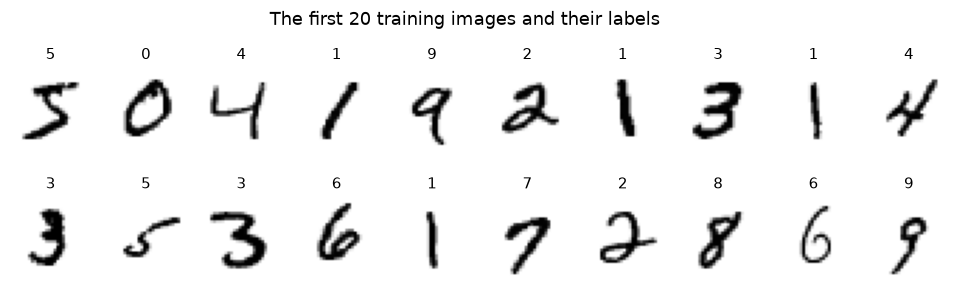

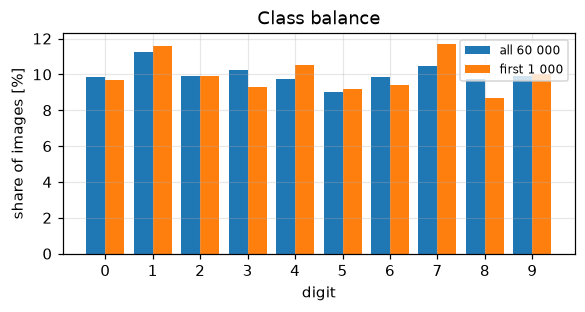

In [5]:
fig, axes = plt.subplots(2, 10, figsize=(11, 2.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images_raw[i], cmap="gray_r")     # gray_r: dark ink on white paper
    ax.set_title(f"{train_labels_raw[i].item()}", fontsize=10)
    ax.axis("off")
fig.suptitle("The first 20 training images and their labels", y=1.02)
plt.show()

fig, ax = plt.subplots(figsize=(6, 2.6))
counts_train = torch.bincount(train_labels_raw, minlength=NUM_CLASSES).float()   # images per digit
counts_first = torch.bincount(train_labels_raw[:1000], minlength=NUM_CLASSES).float()
digits = torch.arange(NUM_CLASSES)
ax.bar(digits - 0.2, counts_train / counts_train.sum() * 100, width=0.4, label="all 60 000")
ax.bar(digits + 0.2, counts_first / counts_first.sum() * 100, width=0.4, label="first 1 000")
ax.set_xticks(range(10)); ax.set_xlabel("digit"); ax.set_ylabel("share of images [%]")
ax.legend(fontsize=8); ax.set_title("Class balance")
plt.show()

## 5. Building blocks

| Code | Equation / section | NumPy twin |
|---|---|---|
| `mse_loss`, `cross_entropy_loss` | 2.4 | the same definitions; here Autograd provides $\partial\mathcal L/\partial Z^{(L)}$ |
| `MLP(nn.Module)` | 2.2, 2.3, 2.9 | `MLP.forward`; `backward` is replaced by Autograd |
| `torch.optim.SGD`, `torch.optim.Adam` | 2.5, 2.11 | hand-written `SGD`, `Adam` |
| `train` | 2.7, 2.10 | the same loop structure |

### 5.1 Loss functions

The MSE is defined exactly as in the NumPy notebook (half squared error, summed over the 10 outputs, averaged over the
batch), so the **same learning rate means the same step** in both notebooks. `F.cross_entropy` accepts raw scores
(it applies log-softmax internally, in a numerically stable way) and, since PyTorch 1.10, also one-hot / probability
targets.

In [6]:
def mse_loss(out, Y):
    """L = (1/B) * sum_i 0.5*||out_i - y_i||^2  (= (C/2) * nn.MSELoss(reduction='mean'))."""
    return 0.5 * ((out - Y) ** 2).sum(dim=1).mean()


def cross_entropy_loss(z, Y):
    """Softmax + cross-entropy on raw scores z with one-hot targets Y (mean over the batch)."""
    return F.cross_entropy(z, Y)


LOSSES = {"mse": mse_loss, "ce": cross_entropy_loss}

# sanity check of the relation to the built-in loss: L_ours = (C/2) * MSELoss
_o, _y = torch.randn(4, NUM_CLASSES), F.one_hot(torch.arange(4), NUM_CLASSES).float()
print(f"mse_loss = {mse_loss(_o, _y).item():.6f},  (C/2)*nn.MSELoss = "
      f"{NUM_CLASSES / 2 * nn.MSELoss()(_o, _y).item():.6f}")

mse_loss = 7.912309,  (C/2)*nn.MSELoss = 7.912308


### 5.2 The multi-layer perceptron as an `nn.Module`

`MLP(sizes=[784, 100, 10])` builds `Linear → ReLU (→ Dropout) → … → Linear` inside an `nn.Sequential`.

* `nn.Linear(n_in, n_out, bias)` holds a `weight` of shape $(n_\text{out}, n_\text{in})$ and computes
  $Z = A\,W^\top + b$ (Section 2.2).
* `nn.Dropout(p)` implements **inverted** dropout (Section 2.9): in `train()` mode it zeroes each element with probability
  $p$ and scales the rest by $1/(1-p)$; in `eval()` mode it is the identity.
* Initialisation is done inside `torch.no_grad()` so that it is not recorded by Autograd:
  `uniform_(-0.1, 0.1)` (Trask) or `nn.init.kaiming_normal_(…, nonlinearity="relu")` = He, $\mathcal N(0, 2/n_\text{in})$.

All parameters are registered automatically; `model.parameters()` hands them to the optimiser and `model.to(device)`
moves them to the GPU. The random numbers differ from NumPy's, so the two notebooks start from different (but
statistically equivalent) weights and their results agree statistically, not digit by digit.

In [7]:
class MLP(nn.Module):
    """Fully-connected ReLU network.

    sizes     : list of layer widths, e.g. [784, 100, 10]
    bias      : include bias vectors
    init      : 'uniform' -> U(-init_scale, init_scale) (Trask);  'he' -> N(0, 2/n_in)
    dropout_p : dropout probability after every hidden ReLU (0 = no dropout layer)
    """

    def __init__(self, sizes, bias=True, init="he", init_scale=0.1, dropout_p=0.0):
        super().__init__()
        self.sizes = list(sizes)
        layers = []
        n_layers = len(sizes) - 1
        for l, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            layers.append(nn.Linear(n_in, n_out, bias=bias))      # Z = A W^T + b
            if l < n_layers - 1:                                   # hidden layer -> non-linearity
                layers.append(nn.ReLU())
                if dropout_p > 0.0:
                    layers.append(nn.Dropout(p=dropout_p))         # active only in model.train()
        self.net = nn.Sequential(*layers)
        self.reset_parameters(init, init_scale)

    @torch.no_grad()                                               # initialisation is not part of the graph
    def reset_parameters(self, init, init_scale):
        for m in self.net:
            if isinstance(m, nn.Linear):
                if init == "uniform":
                    m.weight.uniform_(-init_scale, init_scale)
                elif init == "he":
                    nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
                else:
                    raise ValueError(f"unknown init '{init}'")
                if m.bias is not None:
                    m.bias.zero_()

    def forward(self, x):
        return self.net(x)                                         # raw scores (B, 10)

    def n_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)


torch.manual_seed(SEED)
demo = MLP([INPUT_SIZE, 100, NUM_CLASSES], bias=False, init="uniform", dropout_p=0.5).to(device)
print(demo)
print(f"\n{demo.n_params():,} trainable parameters;", "shapes:", [tuple(p.shape) for p in demo.parameters()])

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=False)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=100, out_features=10, bias=False)
  )
)

79,400 trainable parameters; shapes: [(100, 784), (10, 100)]


### 5.3 Optimisers

PyTorch provides the optimisers of Section 2.11 ready-made:

```python
torch.optim.SGD(model.parameters(), lr=0.1)                 # plain SGD
torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9)   # SGD + momentum
torch.optim.Adam(model.parameters(), lr=1e-3)               # Adam, betas=(0.9, 0.999), eps=1e-8
```

`optimizer.step()` reads `p.grad` of every parameter and updates `p` in place; `optimizer.zero_grad()` clears the
gradients, which otherwise **accumulate** over successive `backward()` calls.

### 5.4 Evaluation and the training loop

`train` is used by **all** experiments and follows the canonical 5-step cycle per mini-batch:

1. `optimizer.zero_grad()` – clear old gradients;
2. `out = model(xb)` – forward pass (dropout active because of `model.train()`);
3. `loss = loss_fn(out, yb)`;
4. `loss.backward()` – Autograd computes $\partial\mathcal L/\partial\theta$ for all parameters (Section 2.6);
5. `optimizer.step()` – update.

After each evaluated epoch the model is switched to `model.eval()` and evaluated under `torch.no_grad()`. If a
validation set is given, the parameters with the lowest validation loss are kept (checkpoint selection) as a cloned
`state_dict`.

**Performance notes.**
* The shuffling permutation is generated by a dedicated CPU `torch.Generator` (works identically on every device) and
  then moved to the device; indexing `X[idx]` happens on the device.
* Running loss and accuracy are accumulated as **tensors** and converted with `.item()` only when they are printed:
  every `.item()` forces the CPU to wait for the GPU.
* The training loss/accuracy are accumulated from the mini-batches during the epoch (dropout on, weights changing), as
  in Trask and in the NumPy twin.

In [8]:
@torch.no_grad()                                         # no graph needed for evaluation
def evaluate(model, X, Y, loss="mse", chunk=10_000):
    """Loss and accuracy on (X, Y) with dropout OFF; processed in chunks to limit memory."""
    was_training = model.training
    model.eval()
    total_loss = torch.zeros((), device=X.device)
    correct = torch.zeros((), device=X.device)
    for s in range(0, len(X), chunk):
        out = model(X[s:s + chunk])
        total_loss += LOSSES[loss](out, Y[s:s + chunk]) * len(out)        # undo the batch mean
        correct += (out.argmax(1) == Y[s:s + chunk].argmax(1)).sum()
    model.train(was_training)
    return total_loss.item() / len(X), correct.item() / len(X)


def train(model, opt, X, Y, epochs, batch_size, loss="mse",
          X_val=None, Y_val=None, X_test=None, Y_test=None,
          eval_every=1, shuffle_gen=None, desc="training", print_every=None):
    """Generic mini-batch training loop. Returns (history, best) where best holds the checkpoint
    with the lowest validation loss (or the final state if no validation set is given)."""
    loss_fn = LOSSES[loss]
    if shuffle_gen is None:
        shuffle_gen = torch.Generator().manual_seed(SEED + 100_000)
    N = len(X)
    hist = {k: [] for k in ("epoch", "train_loss", "train_acc", "val_loss", "val_acc", "test_loss", "test_acc")}
    best = {"epoch": 0, "val_loss": float("inf"), "state": None}

    pbar = tqdm(range(1, epochs + 1), desc=desc, leave=False)
    for epoch in pbar:
        model.train()                                                    # dropout ON
        perm = torch.randperm(N, generator=shuffle_gen).to(X.device)     # shuffle
        run_loss = torch.zeros((), device=X.device)
        run_correct = torch.zeros((), device=X.device)
        for s in range(0, N, batch_size):
            idx = perm[s:s + batch_size]
            xb, yb = X[idx], Y[idx]
            opt.zero_grad(set_to_none=True)                              # 1. clear gradients
            out = model(xb)                                              # 2. forward
            l = loss_fn(out, yb)                                         # 3. loss
            l.backward()                                                 # 4. back-propagation (Autograd)
            opt.step()                                                   # 5. update
            run_loss += l.detach() * len(idx)                            # detach: no graph for bookkeeping
            run_correct += (out.argmax(1) == yb.argmax(1)).sum()

        if epoch % eval_every == 0 or epoch == epochs or epoch == 1:    # evaluation (dropout OFF)
            hist["epoch"].append(epoch)
            hist["train_loss"].append(run_loss.item() / N)
            hist["train_acc"].append(run_correct.item() / N)
            for name, Xe, Ye in (("val", X_val, Y_val), ("test", X_test, Y_test)):
                if Xe is not None:
                    le, ae = evaluate(model, Xe, Ye, loss)
                    hist[f"{name}_loss"].append(le); hist[f"{name}_acc"].append(ae)
            if X_val is not None and hist["val_loss"][-1] < best["val_loss"]:   # checkpoint selection
                best = {"epoch": epoch, "val_loss": hist["val_loss"][-1],
                        "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
            post = {"train_acc": f"{hist['train_acc'][-1]:.3f}"}
            if X_val is not None:  post["val_acc"] = f"{hist['val_acc'][-1]:.3f}"
            if X_test is not None: post["test_acc"] = f"{hist['test_acc'][-1]:.3f}"
            pbar.set_postfix(post)
            if print_every and (epoch % print_every == 0 or epoch == 1 or epoch == epochs):
                tqdm.write(f"epoch {epoch:4d} | " + "  ".join(f"{k} {v}" for k, v in post.items())
                           + f"  train_loss {hist['train_loss'][-1]:.4f}")
    if best["state"] is None:                                            # no validation set: final state
        best = {"epoch": epochs, "val_loss": float("nan"),
                "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
    return hist, best

## 6. Gradient check: what does Autograd compute?

Autograd is not magic – it applies the chain rule of Section 2.6. We verify this twice on a small network in double
precision (`float64`):

1. **Autograd vs. the hand-derived equations.** We compute the gradients with `loss.backward()` and with the four
   boxed back-propagation equations written explicitly with tensor operations. They must agree to rounding error
   ($\sim10^{-15}$).
2. **Autograd vs. finite differences** with `torch.autograd.gradcheck`, which perturbs every input entry by
   $\pm\varepsilon$ and compares the numerical derivative with Autograd's. For the dropout case, the random seed is reset
   inside the function so that every evaluation uses the **same** dropout mask.

`torch.func.functional_call(model, params, x)` evaluates the model with a given dictionary of parameter tensors,
which lets `gradcheck` treat the parameters as ordinary function inputs.

In [9]:
def manual_gradients(model, X, Y, loss):
    """Back-propagation by hand (Section 2.6) for an MLP without dropout, using the model's Linear layers.
    Note: nn.Linear stores weight = W^T, so dL/dweight = (A^T delta)^T = delta^T A."""
    linears = [m for m in model.net if isinstance(m, nn.Linear)]
    A, As, Zs = X, [], []
    with torch.no_grad():
        for l, lin in enumerate(linears):                    # forward pass, storing A^(l-1) and Z^(l)
            As.append(A)
            Z = A @ lin.weight.T + (lin.bias if lin.bias is not None else 0.0)
            Zs.append(Z)
            A = torch.relu(Z) if l < len(linears) - 1 else Z
        B = len(Y)
        delta = (A - Y) / B if loss == "mse" else (torch.softmax(A, dim=1) - Y) / B   # delta^(L)
        grads = {}
        for l in reversed(range(len(linears))):
            grads[f"{l}.weight"] = delta.T @ As[l]           # (A^T delta)^T in nn.Linear layout
            grads[f"{l}.bias"] = delta.sum(0)
            if l > 0:
                delta = (delta @ linears[l].weight) * (Zs[l - 1] > 0)   # delta W^T (math W) * ReLU'
    return grads


torch.manual_seed(0)
X_gc = X_train_full[:8].double()
Y_gc = Y_train_full[:8].double()

print("1) Autograd vs. hand-derived back-propagation")
for loss in ("mse", "ce"):
    net = MLP([INPUT_SIZE, 16, 12, NUM_CLASSES], bias=True, init="he").to(device).double()
    with torch.no_grad():
        for m in net.net:
            if isinstance(m, nn.Linear):
                m.bias.normal_(0, 0.1)                       # non-zero biases so their gradients are tested
    net.zero_grad()
    LOSSES[loss](net(X_gc), Y_gc).backward()                 # Autograd
    man = manual_gradients(net, X_gc, Y_gc, loss)            # by hand
    lin_idx = [i for i, m in enumerate(net.net) if isinstance(m, nn.Linear)]
    worst = 0.0
    for l, i in enumerate(lin_idx):
        for kind in ("weight", "bias"):
            g_auto = getattr(net.net[i], kind).grad
            g_man = man[f"{l}.{kind}"]
            rel = ((g_auto - g_man).abs().max() / g_auto.abs().max().clamp_min(1e-30)).item()
            worst = max(worst, rel)
    print(f"   loss={loss:3s}: max relative difference {worst:.2e}")

print("\n2) Autograd vs. finite differences (torch.autograd.gradcheck)")
for loss in ("mse", "ce"):
    for p in (0.0, 0.5):
        net = MLP([INPUT_SIZE, 16, 12, NUM_CLASSES], bias=True, init="he", dropout_p=p).to(device).double()
        net.train()                                          # dropout active (if p > 0)
        names = [n for n, _ in net.named_parameters()]
        params = tuple(t.detach().clone().requires_grad_(True) for t in net.parameters())

        def f(*ps):
            torch.manual_seed(123)                           # SAME dropout mask in every evaluation
            out = torch.func.functional_call(net, dict(zip(names, ps)), (X_gc,))
            return LOSSES[loss](out, Y_gc)

        ok = torch.autograd.gradcheck(f, params, eps=1e-6, atol=1e-5, rtol=1e-3)
        print(f"   loss={loss:3s}  dropout_p={p:.1f}: gradcheck passed = {ok}")

1) Autograd vs. hand-derived back-propagation
   loss=mse: max relative difference 0.00e+00
   loss=ce : max relative difference 2.99e-16

2) Autograd vs. finite differences (torch.autograd.gradcheck)
   loss=mse  dropout_p=0.0: gradcheck passed = True
   loss=mse  dropout_p=0.5: gradcheck passed = True
   loss=ce   dropout_p=0.0: gradcheck passed = True
   loss=ce   dropout_p=0.5: gradcheck passed = True


## 7. Experiment A – stochastic gradient descent (one image per step)

This reproduces `chapter_8_1` (Trask, ch. 8): the first **1000** training images, network $784\to100\to10$ without biases,
uniform initialisation in $[-0.1, 0.1]$, MSE loss, learning rate $\eta=0.005$ and **one weight update per image**.
Run 1 has no dropout, run 2 uses dropout with $p=0.5$. Both runs start from the same weights.

The images are shuffled every epoch and the test set is evaluated (in one batch of 10 000) every 10 epochs. The test
accuracy is only *monitored*, no decision is based on it.

**Note on speed.** With $B=1$ every step is a handful of tiny operations, so the run time is dominated by Python and
kernel-launch overhead. On a GPU this experiment is often *slower* than on the CPU – exactly the reason why
mini-batches (Experiment B) are used in practice.

**What to look for.** Without dropout the training accuracy reaches 100 % within a few dozen epochs (memorisation)
while the test accuracy peaks early and then slowly *decreases*: overfitting. With dropout the training accuracy stays
below 100 % and the gap between training and test accuracy is smaller. Whether dropout also gives a higher *best* test
accuracy is not guaranteed in this small set-up – a single run cannot decide it; Experiment C examines it properly.

In [10]:
# ---- hyper-parameters of Experiment A (as in chapter_8_1) ---------------------------------------
A_N_TRAIN   = 1000      # first 1000 training images
A_HIDDEN    = 100       # hidden neurons
A_LR        = 0.005     # learning rate eta (Trask: alpha)
A_EPOCHS    = 300       # passes through the 1000 images
A_EVAL      = 10        # evaluate the test set every 10 epochs

X_a, Y_a = X_train_full[:A_N_TRAIN], Y_train_full[:A_N_TRAIN]

results_A = {}
for p in (0.0, 0.5):
    torch.manual_seed(SEED)                                   # same initial weights for both runs
    model = MLP([INPUT_SIZE, A_HIDDEN, NUM_CLASSES], bias=False, init="uniform", init_scale=0.1,
                dropout_p=p).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=A_LR)
    t0 = time.time()
    hist, _ = train(model, opt, X_a, Y_a, epochs=A_EPOCHS, batch_size=1, loss="mse",
                    X_test=X_test, Y_test=Y_test, eval_every=A_EVAL,
                    shuffle_gen=torch.Generator().manual_seed(SEED + 100_000),
                    desc=f"A: SGD, dropout p={p}", print_every=50)
    results_A[p] = {"hist": hist, "time": time.time() - t0}
    best_i = max(range(len(hist["test_acc"])), key=hist["test_acc"].__getitem__)
    print(f"--> dropout p={p}: {results_A[p]['time']:.1f} s, final train acc {hist['train_acc'][-1]:.4f}, "
          f"final test acc {hist['test_acc'][-1]:.4f} (highest monitored: {hist['test_acc'][best_i]:.4f} "
          f"at epoch {hist['epoch'][best_i]})\n")

A: SGD, dropout p=0.0:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.621  test_acc 0.736  train_loss 0.3286
epoch   50 | train_acc 1.000  test_acc 0.879  train_loss 0.0189
epoch  100 | train_acc 1.000  test_acc 0.874  train_loss 0.0071
epoch  150 | train_acc 1.000  test_acc 0.870  train_loss 0.0037
epoch  200 | train_acc 1.000  test_acc 0.869  train_loss 0.0023
epoch  250 | train_acc 1.000  test_acc 0.867  train_loss 0.0016
epoch  300 | train_acc 1.000  test_acc 0.865  train_loss 0.0011
--> dropout p=0.0: 132.3 s, final train acc 1.0000, final test acc 0.8654 (highest monitored: 0.8820 at epoch 40)



A: SGD, dropout p=0.5:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.427  test_acc 0.661  train_loss 0.4238
epoch   50 | train_acc 0.946  test_acc 0.878  train_loss 0.1182
epoch  100 | train_acc 0.970  test_acc 0.879  train_loss 0.0925
epoch  150 | train_acc 0.969  test_acc 0.876  train_loss 0.0907
epoch  200 | train_acc 0.979  test_acc 0.871  train_loss 0.0801
epoch  250 | train_acc 0.976  test_acc 0.872  train_loss 0.0831
epoch  300 | train_acc 0.984  test_acc 0.869  train_loss 0.0735
--> dropout p=0.5: 115.5 s, final train acc 0.9840, final test acc 0.8687 (highest monitored: 0.8794 at epoch 100)



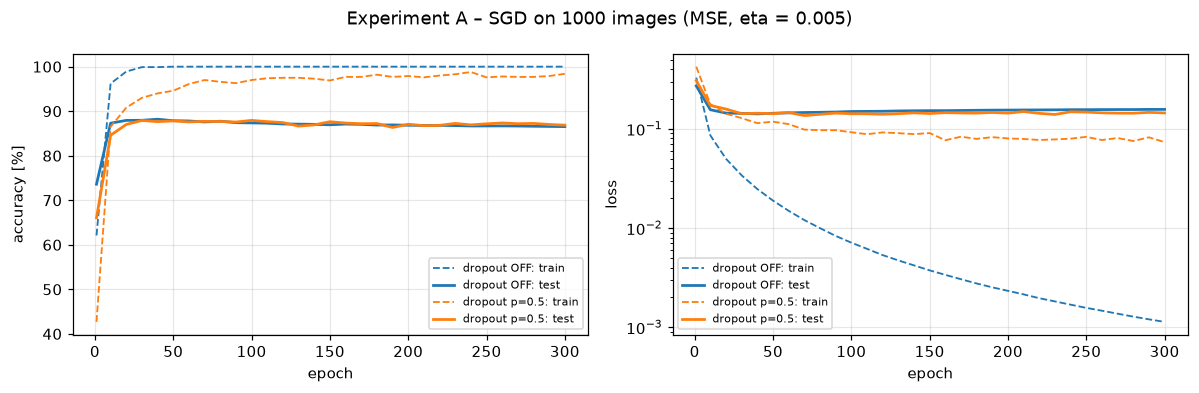

In [11]:
def plot_curves(results, title, labels):
    """Accuracy (train dashed / test or val solid) and loss curves for a dict of runs."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    for (key, res), lab, col in zip(results.items(), labels, ("C0", "C1", "C2", "C3")):
        h = res["hist"]
        ev = "val" if h["val_acc"] else "test"
        a1.plot(h["epoch"], [a * 100 for a in h["train_acc"]], "--", color=col, lw=1.2, label=f"{lab}: train")
        a1.plot(h["epoch"], [a * 100 for a in h[f"{ev}_acc"]], "-", color=col, lw=1.8, label=f"{lab}: {ev}")
        a2.plot(h["epoch"], h["train_loss"], "--", color=col, lw=1.2, label=f"{lab}: train")
        a2.plot(h["epoch"], h[f"{ev}_loss"], "-", color=col, lw=1.8, label=f"{lab}: {ev}")
    a1.set_xlabel("epoch"); a1.set_ylabel("accuracy [%]"); a1.legend(fontsize=7)
    a2.set_xlabel("epoch"); a2.set_ylabel("loss"); a2.set_yscale("log"); a2.legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()


plot_curves(results_A, "Experiment A – SGD on 1000 images (MSE, eta = 0.005)",
            ["dropout OFF", "dropout p=0.5"])

## 8. Experiment B – mini-batch gradient descent

The **correct, vectorised** version of `chapter_8_2_batch`: same images and network, $B=100$ images per update. With
our mean loss the learning rate equivalent to Trask's `alpha = 0.001` (summed loss) is $\eta = B\cdot0.001 = 0.1$
(Section 2.7). In PyTorch "vectorised" comes for free: `model(xb)` processes the whole batch, and `loss.backward()`
sums the per-sample gradients automatically. The "naive" version of Section 2.7 would correspond to calling
`optimizer.step()` $B$ times with the same gradient.

B: mini-batch, dropout p=0.0:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.311  test_acc 0.495  train_loss 0.4510
epoch   50 | train_acc 0.968  test_acc 0.873  train_loss 0.0791
epoch  100 | train_acc 0.994  test_acc 0.882  train_loss 0.0461
epoch  150 | train_acc 1.000  test_acc 0.883  train_loss 0.0314
epoch  200 | train_acc 1.000  test_acc 0.880  train_loss 0.0231
epoch  250 | train_acc 1.000  test_acc 0.882  train_loss 0.0176
epoch  300 | train_acc 1.000  test_acc 0.879  train_loss 0.0140
--> dropout p=0.0: 1.2 s, final train acc 1.0000, final test acc 0.8791 (highest monitored: 0.8835 at epoch 130)



B: mini-batch, dropout p=0.5:   0%|          | 0/300 [00:00<?, ?it/s]

epoch    1 | train_acc 0.198  test_acc 0.428  train_loss 0.5695
epoch   50 | train_acc 0.864  test_acc 0.853  train_loss 0.1693
epoch  100 | train_acc 0.924  test_acc 0.873  train_loss 0.1364
epoch  150 | train_acc 0.944  test_acc 0.875  train_loss 0.1148
epoch  200 | train_acc 0.952  test_acc 0.874  train_loss 0.1060
epoch  250 | train_acc 0.964  test_acc 0.875  train_loss 0.0966
epoch  300 | train_acc 0.960  test_acc 0.876  train_loss 0.0898
--> dropout p=0.5: 1.3 s, final train acc 0.9600, final test acc 0.8759 (highest monitored: 0.8771 at epoch 280)



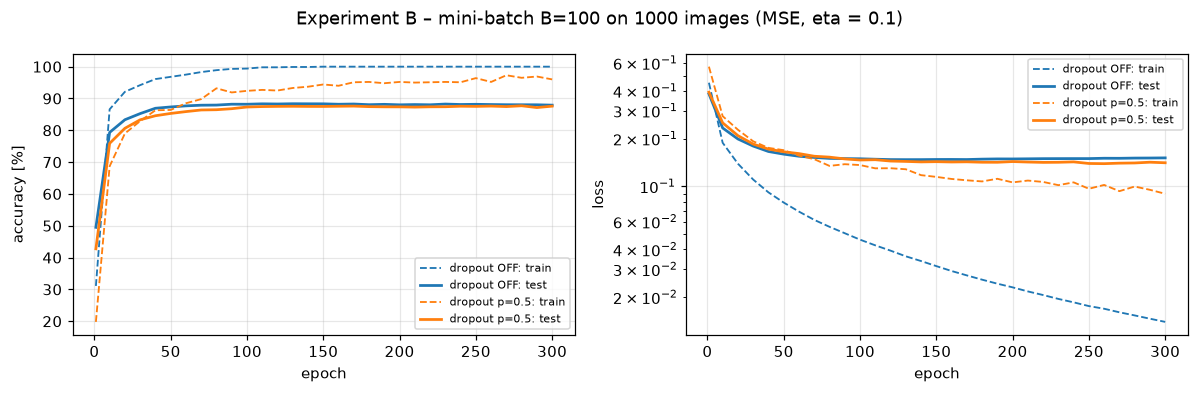

Wall-clock time per run:
  dropout p=0.0:  A (B=1)  132.3 s   |   B (B=100)    1.2 s
  dropout p=0.5:  A (B=1)  115.5 s   |   B (B=100)    1.3 s


In [12]:
B_BATCH  = 100
B_LR     = 0.1           # = 100 * 0.001 (Trask's summed-loss alpha), see Section 2.7
B_EPOCHS = 300

results_B = {}
for p in (0.0, 0.5):
    torch.manual_seed(SEED)
    model = MLP([INPUT_SIZE, A_HIDDEN, NUM_CLASSES], bias=False, init="uniform", init_scale=0.1,
                dropout_p=p).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=B_LR)
    t0 = time.time()
    hist, _ = train(model, opt, X_a, Y_a, epochs=B_EPOCHS, batch_size=B_BATCH, loss="mse",
                    X_test=X_test, Y_test=Y_test, eval_every=A_EVAL,
                    shuffle_gen=torch.Generator().manual_seed(SEED + 100_000),
                    desc=f"B: mini-batch, dropout p={p}", print_every=50)
    results_B[p] = {"hist": hist, "time": time.time() - t0}
    best_i = max(range(len(hist["test_acc"])), key=hist["test_acc"].__getitem__)
    print(f"--> dropout p={p}: {results_B[p]['time']:.1f} s, final train acc {hist['train_acc'][-1]:.4f}, "
          f"final test acc {hist['test_acc'][-1]:.4f} (highest monitored: {hist['test_acc'][best_i]:.4f} "
          f"at epoch {hist['epoch'][best_i]})\n")

plot_curves(results_B, f"Experiment B – mini-batch B={B_BATCH} on 1000 images (MSE, eta = {B_LR})",
            ["dropout OFF", "dropout p=0.5"])

print("Wall-clock time per run:")
for p in (0.0, 0.5):
    print(f"  dropout p={p}:  A (B=1) {results_A[p]['time']:6.1f} s   |   B (B={B_BATCH}) {results_B[p]['time']:6.1f} s")

## 9. Experiment C – dropout ON vs OFF over 5 seeds with checkpoint selection

A single run cannot tell whether dropout helps: the outcome depends on the random initialisation, the shuffling and
the dropout masks. This experiment (from `chapter_8_3_..._master`) therefore uses

| Factor | Setting |
|---|---|
| data | first 1000 training images split into **800 training + 200 validation**; 10 000 test images |
| model | $784\to100\to10$, no biases, uniform init, MSE, mini-batch $B=100$, $\eta=0.1$, 300 epochs |
| conditions | dropout $p=0.5$ (ON) and $p=0$ (OFF) |
| seeds | 1, 2, 3, 4, 5 |
| pairing | for each seed, ON and OFF start from **identical weights** and see the **same batch order** |
| checkpoint | epoch with the lowest **validation** loss, chosen separately for every run |
| test | evaluated **once** per run, with that run's checkpoint |

`torch.manual_seed(seed)` before building the model fixes the initial weights; the dropout masks then draw from the
same global generator. The batch order comes from a dedicated `torch.Generator` seeded with `seed + 100000`, so the
dropout masks cannot change the batch order and the comparison stays paired.

In [13]:
C_SEEDS  = [1, 2, 3, 4, 5]
C_N_VAL  = 200
C_EPOCHS = 300

X_c_tr, Y_c_tr   = X_train_full[:A_N_TRAIN - C_N_VAL], Y_train_full[:A_N_TRAIN - C_N_VAL]       # 800 images
X_c_val, Y_c_val = X_train_full[A_N_TRAIN - C_N_VAL:A_N_TRAIN], Y_train_full[A_N_TRAIN - C_N_VAL:A_N_TRAIN]  # 200

results_C = {}
t0 = time.time()
for seed in C_SEEDS:
    for p, tag in ((0.5, "on"), (0.0, "off")):
        torch.manual_seed(seed)                                                # init (+ dropout masks)
        model = MLP([INPUT_SIZE, A_HIDDEN, NUM_CLASSES], bias=False, init="uniform", init_scale=0.1,
                    dropout_p=p).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=B_LR)
        hist, best = train(model, opt, X_c_tr, Y_c_tr, epochs=C_EPOCHS, batch_size=B_BATCH, loss="mse",
                           X_val=X_c_val, Y_val=Y_c_val, eval_every=1,
                           shuffle_gen=torch.Generator().manual_seed(seed + 100_000),   # batch order only
                           desc=f"C: seed {seed}, dropout {tag}")
        model.load_state_dict(best["state"])                                   # restore the checkpoint
        test_loss, test_acc = evaluate(model, X_test, Y_test, "mse")           # the ONE test evaluation
        results_C[(seed, tag)] = {"hist": hist, "best_epoch": best["epoch"],
                                  "test_acc": test_acc, "test_loss": test_loss}
        print(f"seed {seed}  dropout {tag:3s}: best val epoch {best['epoch']:3d}, test acc {test_acc * 100:.2f} %")
print(f"\nExperiment C finished in {time.time() - t0:.1f} s")

C: seed 1, dropout on:   0%|          | 0/300 [00:00<?, ?it/s]

seed 1  dropout on : best val epoch 227, test acc 87.25 %


C: seed 1, dropout off:   0%|          | 0/300 [00:00<?, ?it/s]

seed 1  dropout off: best val epoch 151, test acc 87.85 %


C: seed 2, dropout on:   0%|          | 0/300 [00:00<?, ?it/s]

seed 2  dropout on : best val epoch 225, test acc 87.18 %


... (10 outputs left out)

C: seed 5, dropout on:   0%|          | 0/300 [00:00<?, ?it/s]

seed 5  dropout on : best val epoch 208, test acc 87.54 %


C: seed 5, dropout off:   0%|          | 0/300 [00:00<?, ?it/s]

seed 5  dropout off: best val epoch 109, test acc 87.70 %

Experiment C finished in 11.4 s


In [14]:
acc_on  = torch.tensor([results_C[(s, "on")]["test_acc"] for s in C_SEEDS]) * 100
acc_off = torch.tensor([results_C[(s, "off")]["test_acc"] for s in C_SEEDS]) * 100
diff    = acc_on - acc_off                                   # paired differences (same seed)

print(f"{'seed':>4} | {'dropout ON':>10} | {'dropout OFF':>11} | {'ON - OFF':>8}")
print("-" * 44)
for s, a, b, d in zip(C_SEEDS, acc_on.tolist(), acc_off.tolist(), diff.tolist()):
    print(f"{s:>4} | {a:>9.2f}% | {b:>10.2f}% | {d:>+7.2f}%")
print("-" * 44)
# torch.std uses the sample standard deviation (Bessel's correction, divide by n-1) by default
print(f"mean | {acc_on.mean():>9.2f}% | {acc_off.mean():>10.2f}% | {diff.mean():>+7.2f}%")
print(f" std | {acc_on.std():>9.2f}% | {acc_off.std():>10.2f}% | {diff.std():>7.2f}%")

if diff.mean() > diff.std():
    verdict = "dropout ON gives consistently higher test accuracy on these seeds"
elif diff.mean() < -diff.std():
    verdict = "dropout OFF gives consistently higher test accuracy on these seeds"
else:
    verdict = "no consistent difference (|mean| < 1 std) - more seeds or more data needed"
print(f"\nVerdict: {verdict}.")
print("(5 seeds measure the sensitivity to training randomness on ONE fixed data split.)")

seed | dropout ON | dropout OFF | ON - OFF
--------------------------------------------
   1 |     87.25% |      87.85% |   -0.60%
   2 |     87.18% |      87.51% |   -0.33%
   3 |     87.73% |      88.03% |   -0.30%
   4 |     87.82% |      87.15% |   +0.67%
   5 |     87.54% |      87.70% |   -0.16%
--------------------------------------------
mean |     87.50% |      87.65% |   -0.14%
 std |      0.28% |       0.34% |    0.48%

Verdict: no consistent difference (|mean| < 1 std) - more seeds or more data needed.
(5 seeds measure the sensitivity to training randomness on ONE fixed data split.)


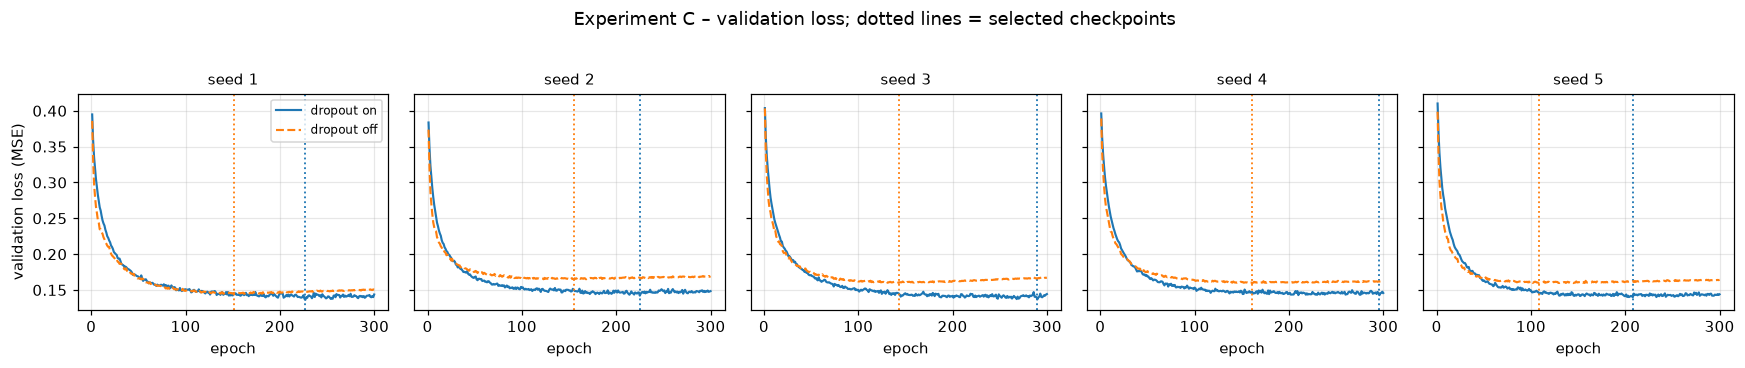

In [15]:
fig, axes = plt.subplots(1, len(C_SEEDS), figsize=(3.2 * len(C_SEEDS), 3.2), sharey=True)
for ax, s in zip(axes, C_SEEDS):
    for tag, col, ls in (("on", "C0", "-"), ("off", "C1", "--")):
        r = results_C[(s, tag)]
        ax.plot(r["hist"]["epoch"], r["hist"]["val_loss"], ls, color=col, lw=1.4, label=f"dropout {tag}")
        ax.axvline(r["best_epoch"], color=col, ls=":", lw=1.2)          # selected checkpoint
    ax.set_title(f"seed {s}", fontsize=10); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation loss (MSE)"); axes[0].legend(fontsize=8)
fig.suptitle("Experiment C – validation loss; dotted lines = selected checkpoints", y=1.03)
plt.tight_layout(); plt.show()

## 10. Experiment D – a modern MLP on the full training set

The previous experiments deliberately used a tiny data set to show overfitting. Now we use the standard ingredients:

| Choice | Experiments A–C | Experiment D | Reason |
|---|---|---|---|
| training data | 800–1000 images | 54 000 (+ 6 000 validation) | more data is the best regulariser |
| architecture | $784\to100\to10$ | $784\to256\to128\to10$ | more capacity, two hidden layers |
| biases | no | yes | lets every unit shift its threshold |
| initialisation | $\mathcal U(-0.1,0.1)$ | He (`kaiming_normal_`) | variance-preserving for ReLU (2.8) |
| loss | MSE | softmax + cross-entropy (`F.cross_entropy`) | standard for classification (2.4b) |
| optimiser | SGD | `torch.optim.Adam`, $\eta=10^{-3}$ | per-parameter step sizes (2.11) |
| dropout | 0 / 0.5 | 0.2 | mild regularisation for a large data set |
| batch size | 1 / 100 | 128 | |

The validation set (the last 6 000 training images) selects the best epoch; the test set is used once at the end.

MLP [784, 256, 128, 10]: 235,146 trainable parameters


D: full MNIST:   0%|          | 0/15 [00:00<?, ?it/s]

epoch    1 | train_acc 0.891  val_acc 0.966  train_loss 0.3611
epoch    2 | train_acc 0.955  val_acc 0.976  train_loss 0.1513
epoch    3 | train_acc 0.968  val_acc 0.977  train_loss 0.1064
epoch    4 | train_acc 0.972  val_acc 0.978  train_loss 0.0879
epoch    5 | train_acc 0.978  val_acc 0.980  train_loss 0.0708
epoch    6 | train_acc 0.981  val_acc 0.982  train_loss 0.0617
epoch    7 | train_acc 0.983  val_acc 0.982  train_loss 0.0530
epoch    8 | train_acc 0.985  val_acc 0.982  train_loss 0.0462
epoch    9 | train_acc 0.986  val_acc 0.982  train_loss 0.0433
epoch   10 | train_acc 0.988  val_acc 0.982  train_loss 0.0378
epoch   11 | train_acc 0.988  val_acc 0.983  train_loss 0.0355
epoch   12 | train_acc 0.989  val_acc 0.985  train_loss 0.0319
epoch   13 | train_acc 0.990  val_acc 0.984  train_loss 0.0293
epoch   14 | train_acc 0.991  val_acc 0.985  train_loss 0.0272
epoch   15 | train_acc 0.992  val_acc 0.980  train_loss 0.0229

training time 4.0 s; best validation epoch 14 (val los

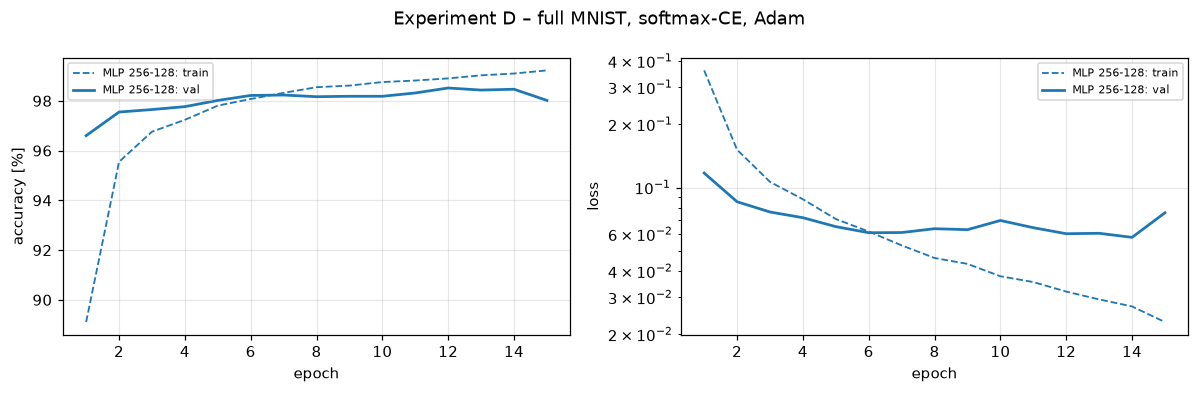

In [16]:
D_N_VAL   = 6000
D_SIZES   = [INPUT_SIZE, 256, 128, NUM_CLASSES]
D_DROPOUT = 0.2
D_LR      = 1e-3
D_BATCH   = 128
D_EPOCHS  = 15

X_d_tr, Y_d_tr   = X_train_full[:-D_N_VAL], Y_train_full[:-D_N_VAL]      # 54 000 images
X_d_val, Y_d_val = X_train_full[-D_N_VAL:], Y_train_full[-D_N_VAL:]      #  6 000 images

torch.manual_seed(SEED)
model_D = MLP(D_SIZES, bias=True, init="he", dropout_p=D_DROPOUT).to(device)
opt_D = torch.optim.Adam(model_D.parameters(), lr=D_LR)
print(f"MLP {D_SIZES}: {model_D.n_params():,} trainable parameters")

t0 = time.time()
hist_D, best_D = train(model_D, opt_D, X_d_tr, Y_d_tr, epochs=D_EPOCHS, batch_size=D_BATCH, loss="ce",
                       X_val=X_d_val, Y_val=Y_d_val, eval_every=1,
                       shuffle_gen=torch.Generator().manual_seed(SEED + 100_000),
                       desc="D: full MNIST", print_every=1)
time_D = time.time() - t0

model_D.load_state_dict(best_D["state"])                               # restore the best checkpoint
test_loss_D, test_acc_D = evaluate(model_D, X_test, Y_test, "ce")      # ONE final test evaluation
print(f"\ntraining time {time_D:.1f} s; best validation epoch {best_D['epoch']} "
      f"(val loss {best_D['val_loss']:.4f})")
print(f"TEST: loss {test_loss_D:.4f}, accuracy {test_acc_D * 100:.2f} % "
      f"({round(test_acc_D * len(X_test))} / {len(X_test)})")

plot_curves({"D": {"hist": hist_D}}, "Experiment D – full MNIST, softmax-CE, Adam", ["MLP 256-128"])

# Optional: save the trained weights (state_dict = dict of tensors) for later use
# torch.save(model_D.state_dict(), "mnist_mlp_D.pt")

## 11. Analysis of the final model

### 11.1 Confusion matrix and per-class accuracy

Entry $(j,k)$ counts the test images of true digit $j$ predicted as $k$. A compact way to build it in PyTorch: encode
each pair as the single integer $10j+k$, count with `torch.bincount` and reshape the 100 counts to $10\times10$.

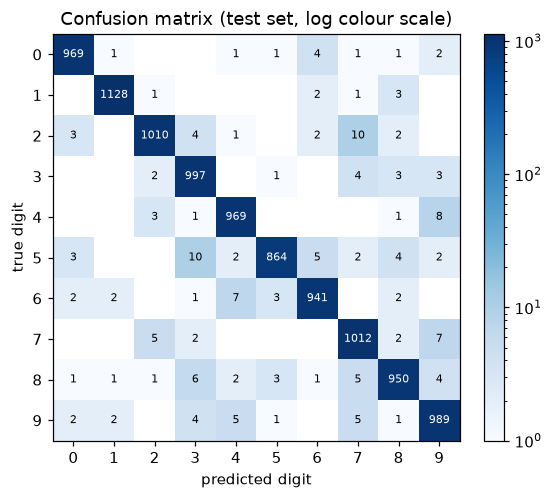

per-class accuracy [%]: 0: 98.9  1: 99.4  2: 97.9  3: 98.7  4: 98.7  5: 96.9  6: 98.2  7: 98.4  8: 97.5  9: 98.0
most frequent confusion: true 2 predicted as 7 (10 times)


In [17]:
model_D.eval()
with torch.no_grad():
    scores_D = model_D(X_test)                               # (10000, 10) raw scores
pred_D = scores_D.argmax(1).cpu()
true_D = test_labels_raw                                     # CPU int64

conf = torch.bincount(true_D * NUM_CLASSES + pred_D, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(conf, cmap="Blues", norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=conf.max().item()))
for j in range(NUM_CLASSES):
    for k in range(NUM_CLASSES):
        c = conf[j, k].item()
        if c:
            ax.text(k, j, c, ha="center", va="center", fontsize=7, color="white" if c > 100 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
ax.set_title("Confusion matrix (test set, log colour scale)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.show()

per_class = conf.diagonal().float() / conf.sum(dim=1).float()
print("per-class accuracy [%]:", "  ".join(f"{d}: {a * 100:.1f}" for d, a in enumerate(per_class.tolist())))
off = conf.clone(); off.fill_diagonal_(0)
j, k = divmod(off.argmax().item(), NUM_CLASSES)
print(f"most frequent confusion: true {j} predicted as {k} ({off[j, k].item()} times)")

### 11.2 The most confident mistakes

Sorting the wrong predictions by the probability the network assigned to its (wrong) answer shows the hardest cases.
Many of them are ambiguous even for a human, some are mislabelled.

171 misclassified test images


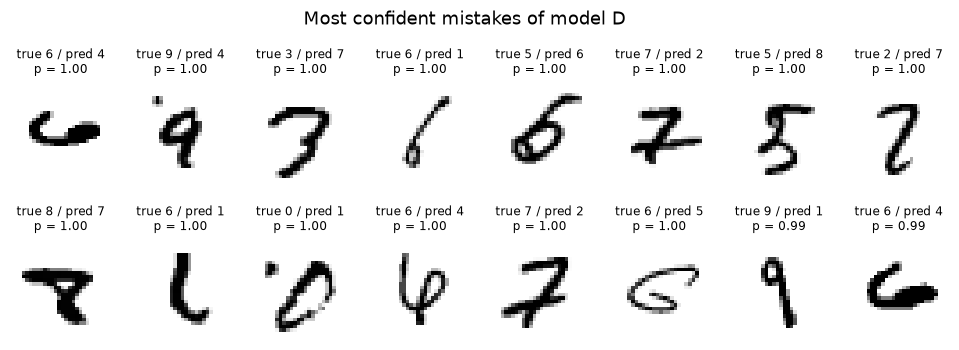

In [18]:
P_test = torch.softmax(scores_D, dim=1).cpu()                # class probabilities
wrong = torch.nonzero(pred_D != true_D).flatten()
conf_wrong = P_test[wrong, pred_D[wrong]]                    # probability of the (wrong) predicted class
order = wrong[torch.argsort(conf_wrong, descending=True)]
print(f"{len(wrong)} misclassified test images")

fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for ax, i in zip(axes.flat, order[:16].tolist()):
    ax.imshow(test_images_raw[i], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"true {true_D[i].item()} / pred {pred_D[i].item()}\np = {P_test[i, pred_D[i]].item():.2f}",
                 fontsize=8)
fig.suptitle("Most confident mistakes of model D", y=1.03); plt.show()

### 11.3 What did the first layer learn?

Each row of the first `nn.Linear` weight (shape $256\times784$) belongs to one hidden unit and can be displayed as a
$28\times28$ image. Red pixels increase, blue pixels decrease the unit's pre-activation. The structured patterns in the
centre are stroke and blob detectors. Pixels near the border are (almost) always 0 in MNIST, so their weights receive
(almost) no gradient and keep their small random initial values – the faint, structureless frame around each
pattern.

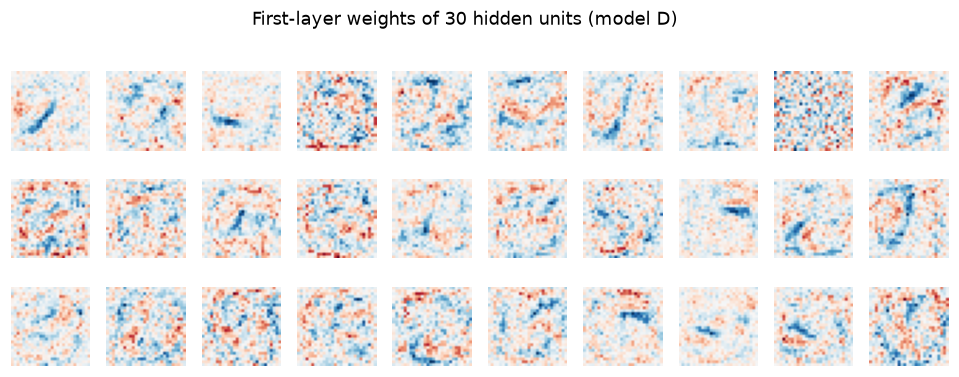

In [19]:
W1 = model_D.net[0].weight.detach().cpu()                    # (256, 784): row j = weights of hidden unit j
fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
for ax, j in zip(axes.flat, range(30)):
    w = W1[j].reshape(28, 28)
    lim = w.abs().max().item()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off")
fig.suptitle("First-layer weights of 30 hidden units (model D)", y=1.02); plt.show()

In [20]:
print(f"Total notebook run time: {(time.time() - T_NOTEBOOK) / 60:.1f} min on {device}")

Total notebook run time: 5.8 min on cuda


## 12. Summary, exercises and references

### 12.1 What we have seen

1. An MLP is a chain of matrix multiplications and element-wise non-linearities; its gradients follow from the
   four back-propagation equations of Section 2.6, verified numerically in Section 6.
2. **Stochastic** gradient descent (one image per step) works but is slow; **mini-batch** descent with one update
   per batch is the correct and efficient generalisation (the "naive" version of `chapter_8_2` applied each batch
   gradient $B$ times).
3. With 1000 training images the network overfits; **dropout** reduces the gap between training and test accuracy.
   Whether it improves the *best* test accuracy must be judged over several seeds and with a validation set
   (Experiment C), not from a single run.
4. More data, He initialisation, biases, softmax + cross-entropy and Adam (Experiment D) raise the test accuracy
   to the level typical of MLPs on MNIST.
5. The twin notebook in NumPy implements the same equations; compare the numbers.

### 12.2 Exercises

| # | Change | Question |
|---|---|---|
| 1 | Experiment A: `lr = 0.05` and `lr = 0.0005` | How do speed and stability change? |
| 2 | Experiment B: `batch_size = 10, 1000` with $\eta$ scaled as in 2.7 | Is the result the same per epoch? per second? |
| 3 | Experiment C: `dropout_p = 0.2, 0.8` | Where is the best trade-off for 800 images? |
| 4 | Experiment D: MSE instead of cross-entropy | How much accuracy is lost? |
| 5 | Experiment D: `hidden = [512, 256, 128]` | Does depth help an MLP on MNIST? |
| 6 | Experiment D: SGD + momentum instead of Adam | Which learning rate is needed? |
| 7 | Section 6: make an error in the back-propagation on purpose | Does the gradient check detect it? |

### 12.3 References

* A. W. Trask, *Grokking Deep Learning*, Manning, 2019 – ch. 4–6 (gradient descent, back-propagation), ch. 8 (overfitting, dropout, batch gradient descent).
* I. Goodfellow, Y. Bengio, A. Courville, *Deep Learning*, MIT Press – ch. 6 (deep feed-forward networks, 6.5 back-propagation),
  ch. 7.12 (dropout), ch. 8.3–8.5 (SGD, momentum, Adam), ch. 8.4 (initialisation).
* Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, "Gradient-based learning applied to document recognition", *Proc. IEEE* 86 (1998) – MNIST.
* N. Srivastava et al., "Dropout: a simple way to prevent neural networks from overfitting", *JMLR* 15 (2014).
* K. He et al., "Delving deep into rectifiers", *ICCV* 2015 – He initialisation.
* D. P. Kingma, J. Ba, "Adam: a method for stochastic optimization", *ICLR* 2015.